In [1]:
!! which ls

['/usr/bin/ls']

In [2]:
print("Hello, World!")

Hello, World!


In [3]:
!! nvidia-smi

['Tue Sep 30 20:08:43 2025       ',
 '+-----------------------------------------------------------------------------------------+',
 '| NVIDIA-SMI 570.153.02             Driver Version: 570.153.02     CUDA Version: 12.8     |',
 '|-----------------------------------------+------------------------+----------------------+',
 '| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |',
 '| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |',
 '|                                         |                        |               MIG M. |',
 '|=========================================+========================+======================|',
 '|   0  NVIDIA GeForce RTX 3070 Ti     Off |   00000000:01:00.0  On |                  N/A |',
 '| 31%   48C    P8             26W /  310W |    1122MiB /   8192MiB |     38%      Default |',
 '|                                         |                        |                  N/A |',
 '+-

In [4]:
import torch
print(torch.__version__)
gpu_available = torch.cuda.is_available()
print(f"GPU available: {gpu_available}")

2.6.0+cu124
GPU available: True


In [22]:
import torch
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader, Dataset
import os

# --- Configuration ---
# Set the root directory of your dataset
DATA_ROOT = 'dataset_spectrograms' # Assuming your 'holdout', 'testing', and 'training' folders are in the current directory

# Define the image size based on your example
IMAGE_SIZE = 128

# Define hyperparameters
BATCH_SIZE = 128
NUM_WORKERS = 0 # Adjust based on your system (number of CPU cores)

# --- 1. Define Transformations ---
# Spectrograms are typically grayscale and need to be converted to tensors,
# normalized, and potentially resized/cropped if your images were of varying sizes.
# Since your images are already 128x128, a simple conversion and normalization will suffice.
data_transforms = transforms.Compose([
    # Convert image to grayscale (since your example is '8-bit grayscale')
    transforms.Grayscale(num_output_channels=1),
    # Convert the PIL image to a PyTorch tensor (H x W x C -> C x H x W)
    transforms.ToTensor(),
    # Normalize the pixel values.
    # For grayscale spectrograms, a mean/std of 0.5 is often a good starting point
    # if you assume values are between 0 and 1 (after ToTensor).
    # You might want to calculate the actual mean/std for better performance later.
    transforms.Normalize(mean=[0.5], std=[0.5])
])

# --- 2. Create Dataset Instances ---
# The ImageFolder class expects the directory structure:
# root/class_x/xxx.png
# root/class_y/yyy.png
# Your structure (training/fake, training/real) fits this perfectly.

# Training dataset
train_dir = os.path.join(DATA_ROOT, 'training')
train_dataset = torchvision.datasets.ImageFolder(
    root=train_dir,
    transform=data_transforms
)

# Testing dataset
test_dir = os.path.join(DATA_ROOT, 'testing')
test_dataset = torchvision.datasets.ImageFolder(
    root=test_dir,
    transform=data_transforms
)

# Holdout dataset (if you want to use it for final validation/testing)
holdout_dir = os.path.join(DATA_ROOT, 'holdout')
# NOTE: The 'holdout' folder in your structure doesn't seem to have 'real'/'fake' subfolders.
# If it follows the same structure as 'testing' and 'training', use:
# holdout_dataset = torchvision.datasets.ImageFolder(
#     root=holdout_dir,
#     transform=data_transforms
# )
# If 'holdout' contains *all* images directly without subfolders, you'd need a custom DataLoader.
# For now, let's assume it *does* have the 'real'/'fake' subfolders for consistency, or skip it.
# Let's assume you'll manually handle the holdout set later if its structure is different.

# --- 3. Create DataLoaders ---
# DataLoaders handle shuffling, batching, and parallel data loading.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True, # Important for training
    num_workers=NUM_WORKERS
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False, # Not necessary for testing
    num_workers=NUM_WORKERS
)
# --- 4. Verification and Inspection ---

print(f"✅ Training data loaded from: {train_dir}")
print(f"✅ Testing data loaded from: {test_dir}")
print("-" * 30)
print(f"Total training samples: {len(train_dataset)}")
print(f"Total testing samples: {len(test_dataset)}")
print(f"Class names (labels): {train_dataset.classes}")
print(f"Class to index mapping: {train_dataset.class_to_idx}")
print("-" * 30)

# Example of fetching one batch
dataiter = iter(train_loader)
images, labels = next(dataiter)

print(f"One batch size (images): {images.shape}") # Should be [BATCH_SIZE, 1, 128, 128]
print(f"One batch size (labels): {labels.shape}") # Should be [BATCH_SIZE]
print(f"Image tensor channel (should be 1 for grayscale): {images.shape[1]}")
print(f"Image tensor dimensions (H x W): {images.shape[2]} x {images.shape[3]}")

✅ Training data loaded from: dataset_spectrograms/training
✅ Testing data loaded from: dataset_spectrograms/testing
------------------------------
Total training samples: 76929
Total testing samples: 11710
Class names (labels): ['fake', 'real']
Class to index mapping: {'fake': 0, 'real': 1}
------------------------------
One batch size (images): torch.Size([128, 1, 128, 128])
One batch size (labels): torch.Size([128])
Image tensor channel (should be 1 for grayscale): 1
Image tensor dimensions (H x W): 128 x 128


In [98]:
import torch.nn as nn
import torch.nn.functional as F

class SpectrogramCNN(nn.Module):
    def __init__(self):
        super(SpectrogramCNN, self).__init__()

        # --- Feature Extractor Blocks ---
        # Block 1: Input 1x128x128 -> Output 32x64x64
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 2: Input 32x64x64 -> Output 64x32x32
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Block 3: Input 64x32x32 -> Output 128x16x16
        self.conv3 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        # Assuming three pooling layers with stride 2, the final feature map size is 128x16x16
        # 128 / 2 / 2 / 2 = 16

        # --- Classifier ---
        # 128 filters * 16 * 16 final spatial dimensions
        self.fc1 = nn.Linear(128 * 16 * 16, 512)
        self.dropout = nn.Dropout(0.7)
        self.fc2 = nn.Linear(512, 2) # 2 output classes: fake and real

    def forward(self, x):
        # Block 1
        x = self.pool1(F.relu(self.bn1(self.conv1(x))))
        # Block 2
        x = self.pool2(F.relu(self.bn2(self.conv2(x))))
        # Block 3
        x = self.pool3(F.relu(self.bn3(self.conv3(x))))

        # Flatten
        x = x.view(-1, 128 * 16 * 16) # Flatten all dimensions except batch size

        # Classifier
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        # Final output layer (No activation here if using CrossEntropyLoss later)
        x = self.fc2(x)
        return x

# Instantiate the model
model = SpectrogramCNN()
print(model) # Uncomment to see the layer details

SpectrogramCNN(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=32768, out_features=512, bias=True)
  (dropout): Dropout(p=0.7, inplace=False)
  (fc2): Linear(in_features=512, out_features=2, bias=True)
)


In [99]:
import torch
import torch.nn as nn
import time
from tqdm.auto import tqdm # For a nice progress bar

# --- 1. Device Configuration ---
# Set the device to CUDA (GPU) if available, otherwise CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# --- 2. Model, Loss, and Optimizer (Recap) ---

# Assume SpectrogramCNN, train_loader, and test_loader are defined from previous steps.

# Instantiate the model and move it to the device
model = SpectrogramCNN().to(device)

# Define the Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0001, weight_decay=1e-3)

# --- 3. Training Loop Configuration ---

# --- 4. The Training Function ---
def train_model(model, criterion, optimizer, train_loader, num_epochs, device):
    print("Starting training...")
    start_time = time.time()

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        # Use tqdm for a visible progress bar
        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}")

        for images, labels in pbar:
            # 🚀 Move data to the configured device (GPU or CPU) 🚀
            images = images.to(device)
            labels = labels.to(device)

            # Zero the parameter gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Backward pass (Backpropagation) and Optimization
            loss.backward()
            optimizer.step()

            # Statistics
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

            # Update progress bar description
            current_loss = running_loss / (pbar.n + 1) # pbar.n is the current number of batches processed
            current_acc = 100 * correct_predictions / total_samples
            pbar.set_postfix({'Loss': f'{current_loss:.4f}', 'Acc': f'{current_acc:.2f}%'})

        epoch_loss = running_loss / len(train_loader)
        epoch_acc = 100 * correct_predictions / total_samples

        print(f"Epoch [{epoch+1}/{num_epochs}], "
              f"Loss: {epoch_loss:.4f}, "
              f"Accuracy: {epoch_acc:.2f}%")

    end_time = time.time()
    total_time = (end_time - start_time) / 60
    print(f"\nTraining finished in {total_time:.2f} minutes.")
    return model

# --- 5. Execution ---

# trained_model = train_model(model, criterion, optimizer, train_loader, NUM_EPOCHS, device)
# Note: You need to have the 'SpectrogramCNN', 'train_loader', and 'device' variables 
# defined and ready from your previous successful steps to run this.

Using device: cuda


In [100]:
import torch
import torch.nn as nn
import time
from tqdm.auto import tqdm 
# ... (Assuming other necessary imports like SpectrogramCNN, etc., are available)

# --- Placeholder for Evaluation Function (Kept separate for clarity) ---
def run_evaluation(model, criterion, test_loader, device):
    """Runs evaluation on the test set and returns average loss and accuracy."""
    model.eval() 
    test_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

    avg_loss = test_loss / len(test_loader)
    accuracy = 100 * correct_predictions / total_samples
    
    return avg_loss, accuracy

# --- The Combined Train and Evaluate Function (MODIFIED) ---

def train_and_evaluate(model, criterion, optimizer, train_loader, test_loader, num_epochs, device):
    print(f"Starting training on {device}...")
    start_time = time.time()
    
    # Initialize dictionary to store metrics
    history = {
        'train_loss': [],
        'train_acc': [],
        'test_loss': [],
        'test_acc': []
    }
    
    best_test_acc = 0.0

    for epoch in range(num_epochs):
        # ----------------------------------------------------
        # 1. TRAINING PHASE
        # ----------------------------------------------------
        model.train()
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} (Train)")

        for images, labels in pbar:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

            current_loss = running_loss / (pbar.n + 1)
            current_acc = 100 * correct_predictions / total_samples
            pbar.set_postfix({'Loss': f'{current_loss:.4f}', 'Acc': f'{current_acc:.2f}%'})

        train_loss = running_loss / len(train_loader)
        train_acc = 100 * correct_predictions / total_samples
        
        # ----------------------------------------------------
        # 2. EVALUATION PHASE
        # ----------------------------------------------------
        test_loss, test_acc = run_evaluation(model, criterion, test_loader, device)

        # ----------------------------------------------------
        # 3. METRIC LOGGING
        # ----------------------------------------------------
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        # ----------------------------------------------------
        # 4. REPORTING
        # ----------------------------------------------------
        print(f"\n--- Epoch {epoch+1}/{num_epochs} ---")
        print(f"TRAIN Loss: {train_loss:.4f} | TRAIN Acc: {train_acc:.2f}%")
        print(f"TEST Loss:  {test_loss:.4f} | TEST Acc:  {test_acc:.2f}%")
        
        # (Optional: Model Saving logic omitted for brevity, but would go here)
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            
        print("-" * 30)

    end_time = time.time()
    total_time = (end_time - start_time) / 60
    print(f"\nTraining finished in {total_time:.2f} minutes.")
    
    # Return the trained model AND the metrics history
    return model, history

In [101]:
NUM_EPOCHS = 10

trained_model, history = train_and_evaluate(model, criterion, optimizer, train_loader, test_loader, NUM_EPOCHS, device)

Starting training on cuda...


Epoch 1/10 (Train):   0%|          | 0/602 [00:00<?, ?it/s]


--- Epoch 1/10 ---
TRAIN Loss: 0.0881 | TRAIN Acc: 97.02%
TEST Loss:  0.0665 | TEST Acc:  98.16%
------------------------------


Epoch 2/10 (Train):   0%|          | 0/602 [00:00<?, ?it/s]


--- Epoch 2/10 ---
TRAIN Loss: 0.0210 | TRAIN Acc: 99.45%
TEST Loss:  0.0240 | TEST Acc:  99.46%
------------------------------


Epoch 3/10 (Train):   0%|          | 0/602 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9/10 (Train):   0%|          | 0/602 [00:00<?, ?it/s]


--- Epoch 9/10 ---
TRAIN Loss: 0.0067 | TRAIN Acc: 99.79%
TEST Loss:  0.0109 | TEST Acc:  99.66%
------------------------------


Epoch 10/10 (Train):   0%|          | 0/602 [00:00<?, ?it/s]


--- Epoch 10/10 ---
TRAIN Loss: 0.0060 | TRAIN Acc: 99.83%
TEST Loss:  0.0173 | TEST Acc:  99.59%
------------------------------

Training finished in 8.28 minutes.


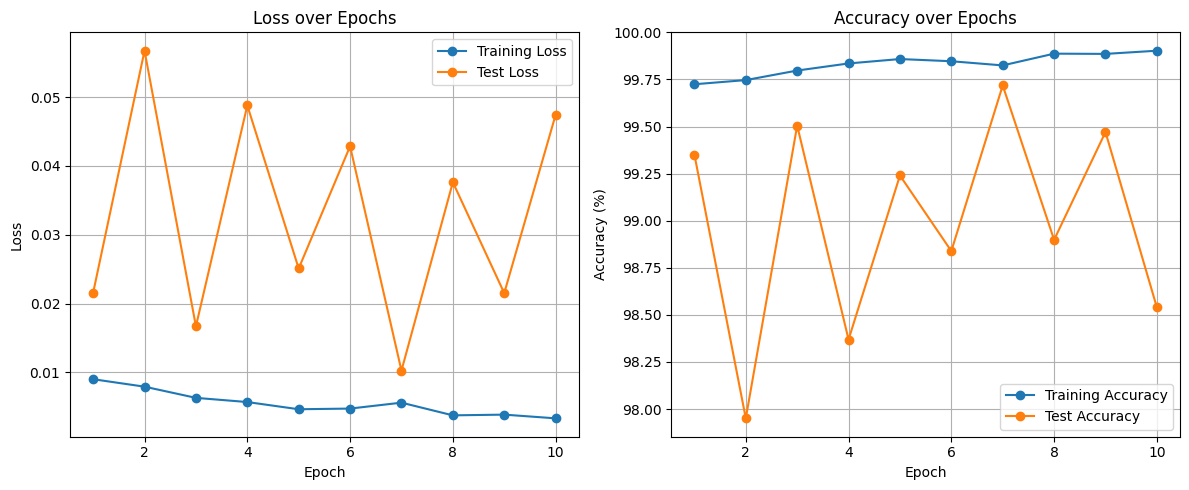

In [97]:
import matplotlib.pyplot as plt

def plot_metrics(history):
    """
    Plots the training and test loss/accuracy over epochs.
    
    Args:
        history (dict): Dictionary containing metric lists: 
                        'train_loss', 'train_acc', 'test_loss', 'test_acc'.
    """
    epochs = range(1, len(history['train_loss']) + 1)
    
    # ----------------------------------------------------
    # Plot 1: Loss
    # ----------------------------------------------------
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, history['train_loss'], label='Training Loss', marker='o')
    plt.plot(epochs, history['test_loss'], label='Test Loss', marker='o')
    plt.title('Loss over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    # ----------------------------------------------------
    # Plot 2: Accuracy
    # ----------------------------------------------------
    plt.subplot(1, 2, 2)
    plt.plot(epochs, history['train_acc'], label='Training Accuracy', marker='o')
    plt.plot(epochs, history['test_acc'], label='Test Accuracy', marker='o')
    plt.title('Accuracy over Epochs')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.grid(True)
    
    plt.tight_layout()
    plt.show()

# --- Example Execution Flow ---
# 1. Run the combined training/evaluation:
# trained_model, metrics_history = train_and_evaluate(
#     model, criterion, optimizer, train_loader, test_loader, NUM_EPOCHS, device
# )

# 2. Plot the results:
plot_metrics(history)

In [58]:
import torch
from tqdm.auto import tqdm # For the progress bar
import numpy as np

def run_evaluation(model, criterion, test_loader, device):
    # Set the model to evaluation mode
    model.eval() 

    test_loss = 0.0
    correct_predictions = 0
    total_samples = 0
    
    # Store all true labels and predictions
    all_labels = []
    all_predictions = []

    print("Starting evaluation...")
    
    # Disable gradient calculation
    with torch.no_grad():
        # Add the tqdm progress bar (the "loading screen")
        pbar = tqdm(test_loader, desc="Evaluating Model")
        
        for images, labels in pbar:
            # Move data to the device
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            # Get predictions
            _, predicted = torch.max(outputs.data, 1)
            
            # Record results for metrics
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())
            
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()
            
            # Update progress bar
            current_loss = test_loss / (pbar.n + 1)
            current_acc = 100 * correct_predictions / total_samples
            pbar.set_postfix({'Loss': f'{current_loss:.4f}', 'Acc': f'{current_acc:.2f}%'})

    # Calculate final metrics for summary
    avg_loss = test_loss / len(test_loader)
    accuracy = 100 * correct_predictions / total_samples
    
    return avg_loss, accuracy, all_labels, all_predictions

In [59]:
avg_loss, accuracy, all_labels, all_predictions = run_evaluation(model, criterion, test_loader, device)

Starting evaluation...


Evaluating Model:   0%|          | 0/92 [00:00<?, ?it/s]


       ✅ Evaluation Results ✅
Test Loss: 0.0131
Test Accuracy: 99.64%


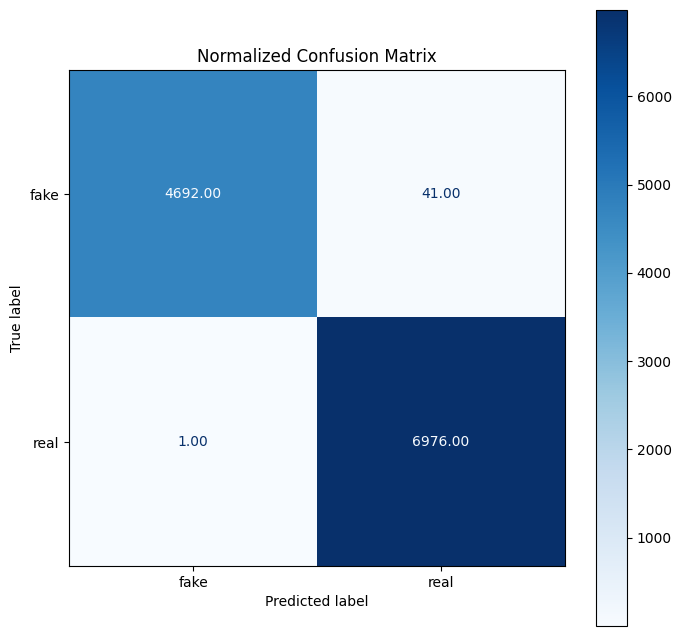

In [62]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = test_loader.dataset.classes 

print("\n" + "=" * 40)
print(f"       ✅ Evaluation Results ✅")
print("=" * 40)
print(f"Test Loss: {avg_loss:.4f}")
print(f"Test Accuracy: {accuracy:.2f}%")
print("=" * 40)

# --- Confusion Matrix Plotting ---

# Generate the confusion matrix
cm = confusion_matrix(all_labels, all_predictions)

# Plot the confusion matrix
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

# Normalize to show percentages
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format=".2f")

ax.set_title("Normalized Confusion Matrix")
plt.show()